<a href="https://colab.research.google.com/github/nidhigadekar2764-png/bank_marketing_uci.ipynb/blob/main/bank_marketing_uci.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
,ni9pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
bank_marketing = fetch_ucirepo(id=222)

# data (as pandas dataframes)
x = bank_marketing.data.features
y = bank_marketing.data.targets



In [ ]:
x.head()

In [ ]:
y.head()

In [ ]:
# Total Customers

x.shape[0]


In [ ]:
# Total Features

x.shape[1]

In [ ]:
# Numerical col

x.select_dtypes(include='number').columns

In [ ]:
# Categorical Cols

x.select_dtypes(include='object').columns

In [ ]:
# Target

y.head(200)

In [ ]:
# Check missing values

x.isnull().sum()

In [ ]:
# Check duplicates

x.duplicated().sum()

In [ ]:
x.describe()

In [ ]:
y.value_counts()

In [ ]:
# Replace missing values with "unknown"

x = x.fillna('unknown')

# **EDA**

In [ ]:
df = x.copy()
df['y'] = y['y']

In [ ]:
df.head()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
px.histogram(df,x='age')

In [ ]:
# Age

px.box(df,x='y',y='age',color='y',title="Age vs Yes/No")

In [ ]:
# Job

px.histogram(df,x='job',color='y',barnorm='percent')

In [ ]:
px.histogram(df,x='job',color='y')

In [ ]:
# Marital

px.histogram(df,x='marital',color='y',barnorm='percent')

In [ ]:
px.histogram(df,x='education',color='y',barnorm='percent')

In [ ]:
# default col

px.histogram(df,x='default',color='y',barnorm='percent')

In [ ]:
# balance col

px.box(df, x='y',y='balance',color='y')

In [ ]:
# housing

px.histogram(df,x='housing',color='y',barnorm='percent')

In [ ]:
# loan

px.histogram(df,x='loan',color='y',barnorm='percent')

In [ ]:
# contact

px.histogram(df,x='contact',color='y',barnorm='percent')

In [ ]:
# day of week

px.histogram(df,x='day_of_week',color='y',barnorm='percent',nbins=31)

In [ ]:
df['term_dp'] = df['y'].map({'yes':100,'no':0})

In [ ]:
px.density_heatmap(df,x='day_of_week',y='month',z='term_dp',histfunc='avg',nbinsx=31)

In [ ]:
df.columns

In [ ]:
# duration

px.histogram(df,x='duration')

In [ ]:
# duration vs term_dp

px.box(df,x='y',y='duration',color='y')

In [ ]:
df.head()

In [ ]:

# Correlation heatmap

corr = df.corr(numeric_only=True)

In [ ]:
px.imshow(corr,text_auto='.2f',color_continuous_scale='RdBu')

In [1]:
# Importing ML Libraries

from sklearn.tree import DecisionTreeClassifier #1
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC #4
from sklearn.neighbors import KNeighborsClassifier #3
from sklearn.linear_model import LogisticRegression #2
from xgboost import XGBClassifier

# **1. Logistic Regression**

In [ ]:
x.columns

In [ ]:
y.columns

In [ ]:
x.head()

In [ ]:
# dropping duration col

x = x.drop(columns=['duration'])

In [ ]:
x.columns

In [ ]:
y.head()

In [ ]:
# encode target variable into 1 and 0

y = y['y'].map({'yes':1,'no':0})

In [ ]:
x.columns

In [ ]:
# Encoding category columns

x = pd.get_dummies(x,drop_first=True,dtype=int)

In [ ]:
x.columns

In [ ]:
x.head()

# **Train-Test Split**

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x.shape

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x,y,test_size=0.2, random_state=42,stratify=y
)

In [ ]:
y.value_counts(normalize=True)*100

In [ ]:
y_train.value_counts(normalize=True)*100

In [ ]:
y_test.value_counts(normalize=True)*100

# **1. Decision Tree**

In [ ]:
dt = DecisionTreeClassifier(random_state=42)

In [ ]:
dt.fit(x_train,y_train)

In [ ]:
from sklearn.tree import plot_tree

In [ ]:
dt.get_depth()

In [ ]:
dt_small = DecisionTreeClassifier(max_depth=2,random_state=42)

In [ ]:
dt_small.fit(x_train,y_train)

In [ ]:
plt.figure(figsize=(28,25))
plot_tree(dt_small,feature_names=x_train.columns,class_names=['No','Yes'],fontsize = 14, filled=True,rounded=True)

In [ ]:
dt_pred = dt.predict(x_test)

In [ ]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score,roc_curve

In [ ]:
# confusion matrix

cm = confusion_matrix(y_test,dt_pred)
cm

In [ ]:
px.imshow(cm,x=['no','yes'],y=['no','yes'],labels={'x':'prediction','y':'actual'},color_continuous_scale='blues_r',text_auto=True,template="plotly_dark")

In [ ]:
# Accuracy

print("Accuracy Score: ",accuracy_score(y_test,dt_pred))

In [ ]:
# Precision, Recall, F1-Score

print("Precision Score: ",precision_score(y_test,dt_pred))

In [ ]:
print("Recall Score: ",recall_score(y_test,dt_pred))

In [ ]:
print("F1 Score: ",f1_score(y_test,dt_pred))

In [ ]:
print("Classification Report: ",classification_report(y_test,dt_pred))

# Auc Roc

In [ ]:
# 1

dt_prob = dt.predict_proba(x_test)[:,1]

In [ ]:
# 2

roc_auc_score(y_test,dt_prob)

In [ ]:
# 3

fpr,tpr,threshold = roc_curve(y_test,dt_prob)

In [ ]:
# 4

fig = px.line(title='Decison Tree ROC Curve',x=fpr,y=tpr,labels={'x':'False Positive Rate','y':'True Positive Rate'})

fig.update_traces(mode='lines+markers',customdata=threshold,
    hovertemplate=(
        "<b>Decision Tree</b><br>"
        "False Positive Rate: $%{x:,.0f}<br>"
        "True Positive Rate: %{y:.1f}<br>"
        "Threshold: %{customdata:.2f}"
        "<extra></extra>"
    )
)

In [ ]:
# 4

px.line(title='Decison Tree ROC Curve',x=fpr,y=tpr,labels={'x':'False Positive Rate','y':'True Positive Rate'})



# **2. Logistic Reg**

# Precision = 0.29

# Accuracy = 0.89

# Recall = 0.33

# F1-Score = 0.94

In [ ]:
x.head()

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()

In [ ]:
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)

In [ ]:
x_train.head()

,age,balance,day_of_week,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
24001,36,861,29,2,-1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
43409,24,4126,5,4,185,7,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20669,44,244,12,4,-1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
18810,48,0,31,11,-1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
23130,38,257,26,10,-1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [ ]:
x_train_s[:10]

# Model Train

In [ ]:
lr = LogisticRegression()

In [ ]:
lr.fit(x_train_s,y_train)

n

# Prediction

In [ ]:
y_pred_lr = lr.predict(x_test_s)

In [ ]:
y_pred_lr

# Metrics

In [ ]:
cm_lr = confusion_matrix(y_test,y_pred_lr)
cm_lr

In [ ]:
px.imshow(cm_lr,x=['no','yes'],y=['no','yes'],labels={'x':'prediction','y':'actual'},color_continuous_scale='blues_r',text_auto=True,template="plotly_dark")

In [ ]:
print("Classification Report: ",classification_report(y_test,y_pred_lr))

Classification Report:                precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.67      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043



In [ ]:
print("F1 Score: ",f1_score(y_test,y_pred_lr))

F1 Score:  0.28294862248696945


In [ ]:
print("Recall Score: ",recall_score(y_test,y_pred_lr))

In [ ]:
print("Precision Score: ",precision_score(y_test,y_pred_lr))

Precision Score:  0.6666666666666666


# **3. KNN**

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)

In [ ]:
x_train.head()

,age,balance,day_of_week,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
24001,36,861,29,2,-1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
43409,24,4126,5,4,185,7,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20669,44,244,12,4,-1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
18810,48,0,31,11,-1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
23130,38,257,26,10,-1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


# **4.SVM**

In [ ]:
svm = SVC(kernel='rbf')

In [ ]:
svm.fit(x_train_s,y_train)

SVC()

In [ ]:
y_pred_svm = svm.predict(x_test_s)

In [ ]:
cm_svm = confusion_matrix(y_test,y_pred_svm)
cm_svm

array([[7868,  117],
       [ 840,  218]])

In [ ]:
x_train_s  = pd.DataFrame(x_train_s,columns=x_train.columns,index=x_train.index)

In [ ]:
x_vis = x_train_s[['age','balance']]

In [ ]:
y_vis = y_train

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay

In [ ]:
model = SVC(kernel='rbf',class_weight='balanced')
model.fit(x_vis,y_vis)

SVC(class_weight='balanced')

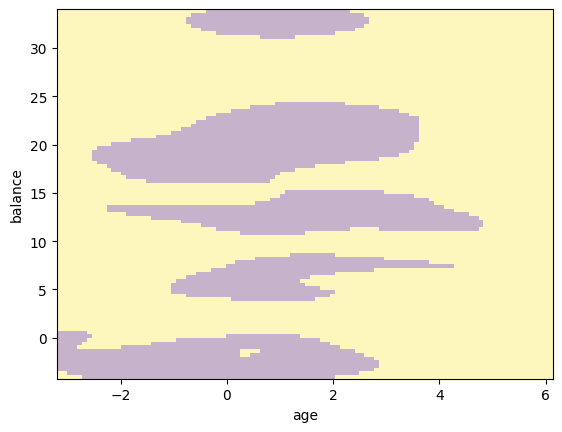

In [ ]:
DecisionBoundaryDisplay.from_estimator(
    model,x_vis,response_method="predict",
        plot_method="pcolormesh",
        alpha=0.3,cmap='viridis',ax=plt.gca()
)

In [ ]:
from sklearn import svm
from sklearn.inspection import DecisionBoundaryDisplay

x_sample = x_vis.sample(500,random_state=42)
y_sample = y_vis.loc[x_sample.index]

X = x_sample.to_numpy()
y = y_sample

def plot_training_data_with_decision_boundary(
    kernel, ax=None, long_title=True, support_vectors=True
):
    # Train the SVC
    clf = svm.SVC(kernel=kernel, class_weight='balanced').fit(X, y)

    # Settings for plotting
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 3))
    x_min, x_max, y_min, y_max = -3, 3, -3, 3
    ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max))

    # Plot decision boundary and margins
    common_params = {"estimator": clf, "X": X, "ax": ax}
    DecisionBoundaryDisplay.from_estimator(
        **common_params,
        response_method="predict",
        plot_method="pcolormesh",
        alpha=0.3,
    )
    DecisionBoundaryDisplay.from_estimator(
        **common_params,
        response_method="decision_function",
        plot_method="contour",
        levels=[-1, 0, 1],
        colors=["k", "k", "k"],
        linestyles=["--", "-", "--"],
    )

    if support_vectors:
        # Plot bigger circles around samples that serve as support vectors
        ax.scatter(
            clf.support_vectors_[:, 0],
            clf.support_vectors_[:, 1],
            s=150,
            facecolors="none",
            edgecolors="k",
        )

    # Plot samples by color and add legend
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, s=30, edgecolors="k")
    ax.legend(*scatter.legend_elements(), loc="upper right", title="Classes")
    if long_title:
        ax.set_title(f" Decision boundaries of {kernel} kernel in SVC")
    else:
        ax.set_title(kernel)

    if ax is None:
        plt.show()



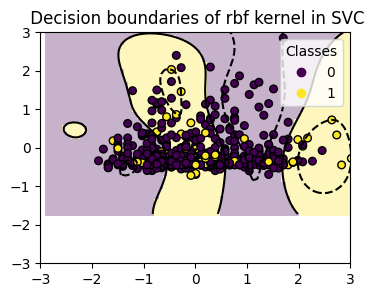

In [ ]:
plot_training_data_with_decision_boundary('rbf',support_vectors=False)
plt.show()

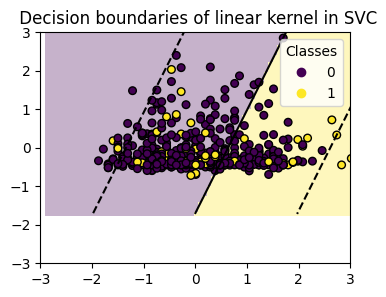

In [ ]:
plot_training_data_with_decision_boundary('linear',support_vectors=False)
plt.show()

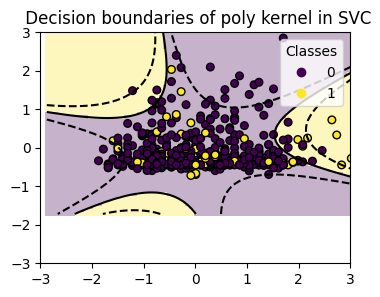

In [ ]:
plot_training_data_with_decision_boundary('poly',support_vectors=False)
plt.show()

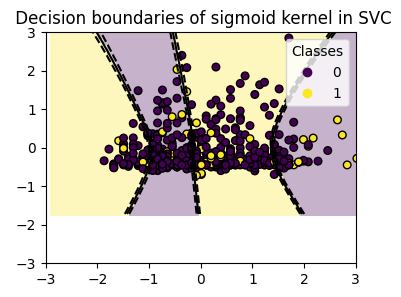

In [ ]:
plot_training_data_with_decision_boundary('sigmoid',support_vectors=False)
plt.show()